# 05 · Ensambles
Bagging (paralelo), boosting (secuencia) y Voting/Stacking (combinar modelos distintos).

In [1]:
# Librerías base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones compartidas del proyecto (métricas, gráficas, rutas) -> archivo churn_utils.py
from churn_utils import *

pd.options.display.max_columns = None
plt.rcParams["figure.dpi"] = 100

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, classification_report
import time

In [2]:
# Cargar los datos ya preparados por el notebook 00 (mismo train/test para TODOS los modelos)
datos = cargar_datos_modelo()
X_train, X_test = datos["X_train"], datos["X_test"]
y_train, y_test = datos["y_train"], datos["y_test"]

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print("Tasa de fuga en train: %.2f%% | en test: %.2f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

Entrenamiento: (8101, 33) | Test: (2026, 33)
Tasa de fuga en train: 16.07% | en test: 16.04%


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

## 1. Un solo árbol de decisión

In [4]:
for profundidad in [3, 6, None]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA).fit(X_train, y_train)
    print(f"max_depth={str(profundidad):<5} AUC train: {roc_auc_score(y_train, arbol.predict_proba(X_train)[:, 1]):.4f}"
          f"  | AUC test: {roc_auc_score(y_test, arbol.predict_proba(X_test)[:, 1]):.4f}")

max_depth=3     AUC train: 0.9194  | AUC test: 0.9118
max_depth=6     AUC train: 0.9755  | AUC test: 0.9671


max_depth=None  AUC train: 1.0000  | AUC test: 0.8904


* Sin límite de profundidad sobreajusta (AUC train 1,00, test 0,89).

## 2. Random Forest
### 2.1 Por defecto

Métricas del modelo: Random Forest (por defecto)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1681   63]
 [  20  262]]
 Accuracy        : 0.9590
 Sensibilidad    : 0.8062
 Especificidad   : 0.9882
 Precision (VPP) : 0.9291
 VPN             : 0.9639
 F1              : 0.8633
 AUC             : 0.9891
 PR-AUC          : 0.9543


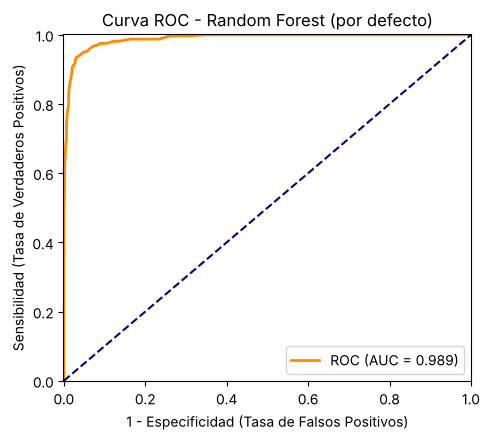

In [5]:
Classifier_RF = RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)
Classifier_RF.fit(X_train, y_train)

y_pred_prob = Classifier_RF.predict_proba(X_test)[:, 1]   # Probabilidades
metricas_rf_default = evaluar_modelo("Random Forest (por defecto)", y_test, y_pred_prob)

### 2.2 Error OOB vs. número de árboles

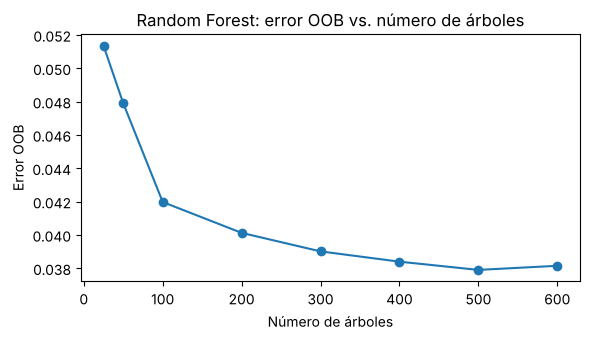

In [6]:
rf_oob = RandomForestClassifier(warm_start=True, oob_score=True, random_state=SEMILLA, n_jobs=-1)
n_trees, oob = [25, 50, 100, 200, 300, 400, 500, 600], []
for t in n_trees:
    rf_oob.set_params(n_estimators=t).fit(X_train, y_train)
    oob.append(1 - rf_oob.oob_score_)
plt.figure(figsize=(6, 3.5)); plt.plot(n_trees, oob, marker="o")
plt.xlabel("Número de árboles"); plt.ylabel("Error OOB"); plt.title("Random Forest: error OOB vs. número de árboles")
plt.tight_layout(); plt.show()

* El error se estabiliza después de ~200–300 árboles.

### 2.3 GridSearchCV

In [7]:
param_grid = {"n_estimators": [300],
              "max_features": ["sqrt", 0.5],
              "min_samples_leaf": [1, 3],
              "class_weight": [None, "balanced_subsample"]}
inicio = time.time()
grid_searchRF = GridSearchCV(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1), param_grid, cv=cv,
                             scoring="roc_auc", return_train_score=True, n_jobs=1).fit(X_train, y_train)
print("Tiempo: %.1f s" % (time.time() - inicio))
print("Mejores hiperparámetros:", grid_searchRF.best_params_)
print("Mejor AUC validación cruzada: %.4f" % grid_searchRF.best_score_)

Tiempo: 89.3 s
Mejores hiperparámetros: {'class_weight': 'balanced_subsample', 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
Mejor AUC validación cruzada: 0.9891


Métricas del modelo: Random Forest (ajustado)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1689   71]
 [  12  254]]
 Accuracy        : 0.9590
 Sensibilidad    : 0.7815
 Especificidad   : 0.9929
 Precision (VPP) : 0.9549
 VPN             : 0.9597
 F1              : 0.8596
 AUC             : 0.9910
 PR-AUC          : 0.9573


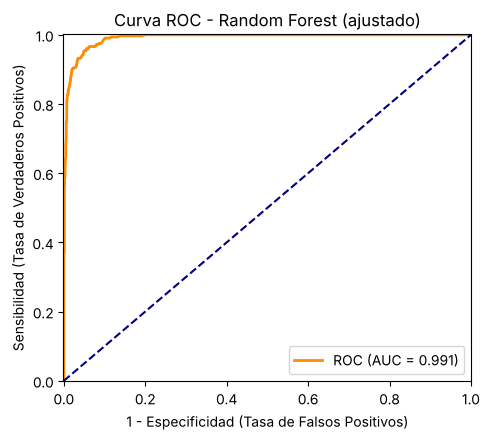

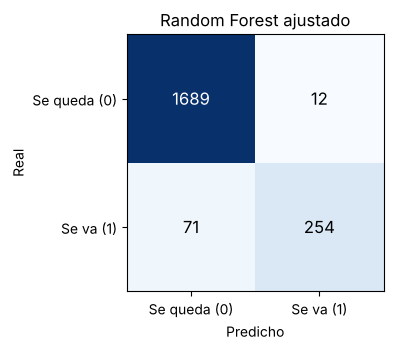

Resultados guardados en: resultados/Random_Forest.pkl


In [8]:
y_pred_prob_rf = grid_searchRF.predict_proba(X_test)[:, 1]
metricas_rf = evaluar_modelo("Random Forest (ajustado)", y_test, y_pred_prob_rf)
plot_confusion(y_test, np.where(y_pred_prob_rf > 0.5, 1, 0), "Random Forest ajustado")
guardar_resultados("Random Forest", y_test, y_pred_prob_rf, metricas_rf, grid_searchRF.best_params_)

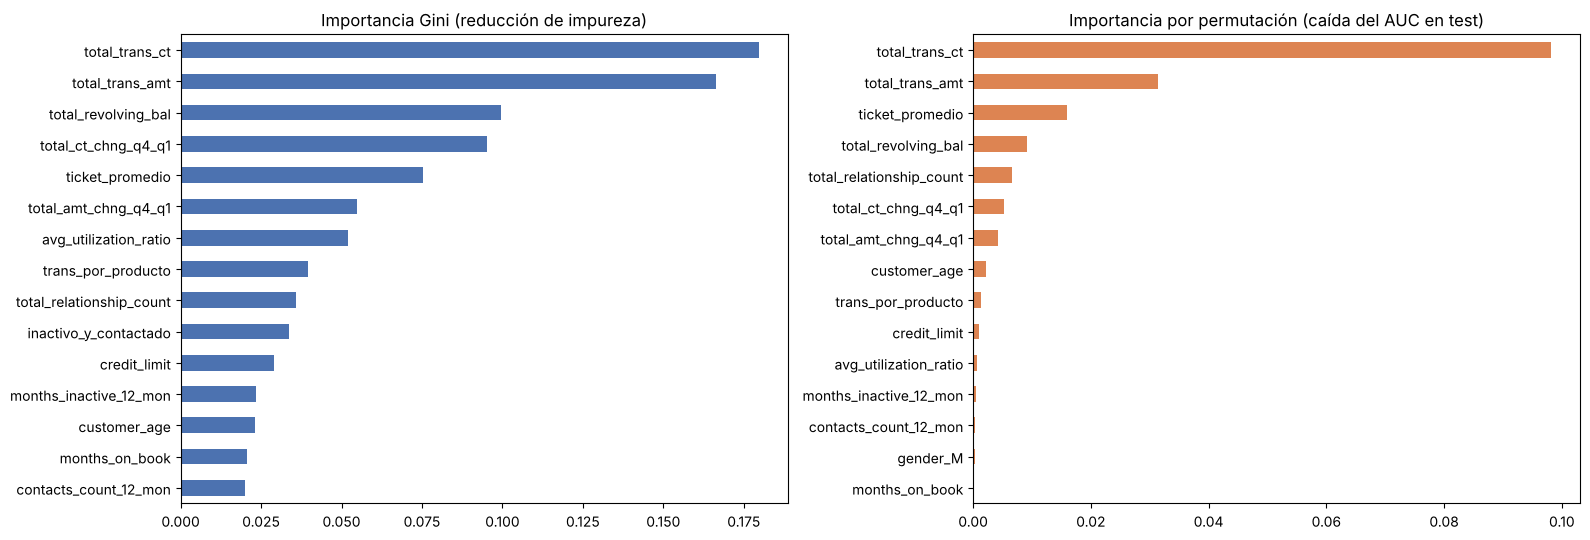

In [9]:
# Variables más importantes: importancia por Gini vs. importancia por permutación
importances = pd.Series(grid_searchRF.best_estimator_.feature_importances_, index=X_train.columns)
perm = permutation_importance(grid_searchRF.best_estimator_, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=SEMILLA, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
importances.nlargest(15).sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Importancia Gini (reducción de impureza)")
perm_imp.nlargest(15).sort_values().plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("Importancia por permutación (caída del AUC en test)")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/rf_importancia.png", bbox_inches="tight"); plt.show()

* Gini y permutación coinciden: transacciones, saldo rotativo y productos.

## 3. Bagging, Extra Trees y AdaBoost

In [10]:
otros = {
    "Bagging (árboles)": BaggingClassifier(DecisionTreeClassifier(random_state=SEMILLA), n_estimators=300,
                                           random_state=SEMILLA, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=500, min_samples_leaf=1, max_features=0.5,
                                        random_state=SEMILLA, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=400, learning_rate=0.5,
                                   random_state=SEMILLA),
}
filas = []
for nombre, modelo in otros.items():
    inicio = time.time()
    auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    modelo.fit(X_train, y_train)
    prob = modelo.predict_proba(X_test)[:, 1]
    m = evaluar_modelo(nombre, y_test, prob, graficar=False); print()
    guardar_resultados(nombre, y_test, prob, m)
    filas.append({"Modelo": nombre, "AUC CV": auc_cv.mean(), "AUC test": m["AUC"], "F1 test": m["F1"], "seg": time.time() - inicio})
pd.DataFrame(filas).round(4)

Métricas del modelo: Bagging (árboles)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1668   33]
 [  33  292]]
 Accuracy        : 0.9674
 Sensibilidad    : 0.8985
 Especificidad   : 0.9806
 Precision (VPP) : 0.8985
 VPN             : 0.9806
 F1              : 0.8985
 AUC             : 0.9900
 PR-AUC          : 0.9544

Resultados guardados en: resultados/Bagging_(árboles).pkl


Métricas del modelo: Extra Trees  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1676   60]
 [  25  265]]
 Accuracy        : 0.9580
 Sensibilidad    : 0.8154
 Especificidad   : 0.9853
 Precision (VPP) : 0.9138
 VPN             : 0.9654
 F1              : 0.8618
 AUC             : 0.9874
 PR-AUC          : 0.9476

Resultados guardados en: resultados/Extra_Trees.pkl


Métricas del modelo: AdaBoost  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1671   45]
 [  30  280]]
 Accuracy        : 0.9630
 Sensibilidad    : 0.8615
 Especificidad   : 0.9824
 Precision (VPP) : 0.9032
 VPN             : 0.9738
 F1              : 0.8819
 AUC             : 0.9919
 PR-AUC          : 0.9624

Resultados guardados en: resultados/AdaBoost.pkl


,Modelo,AUC CV,AUC test,F1 test,seg
0,Bagging (árboles),0.9854,0.9900,0.8985,35.6973
1,Extra Trees,0.9872,0.9874,0.8618,16.2909
2,AdaBoost,0.9912,0.9919,0.8819,36.2045


## 4. Voting y Stacking
Usan los mejores hiperparámetros de los notebooks 02 y 04.

In [11]:
res_previos = cargar_resultados()
p_gbm = res_previos.get("Gradient Boosting", {}).get("mejores_parametros") or {"n_estimators": 400, "learning_rate": 0.1, "max_depth": 3}
p_svm = res_previos.get("SVM RBF", {}).get("mejores_parametros") or {"SVM__C": 10, "SVM__gamma": 0.01}
p_svm = {k.replace("SVM__", ""): v for k, v in p_svm.items()}
print("Parámetros GBM (notebook 04):", p_gbm)
print("Parámetros SVM (notebook 02):", p_svm)

modelos_base = [
    ("gbm", GradientBoostingClassifier(random_state=SEMILLA, **p_gbm)),
    ("rf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1, **grid_searchRF.best_params_)),
    ("svm", Pipeline([("sc", StandardScaler()), ("svm", SVC(kernel="rbf", probability=True, random_state=SEMILLA, **p_svm))])),
    ("logit", Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=2000))])),
]

Parámetros GBM (notebook 04): {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400, 'subsample': 1.0}
Parámetros SVM (notebook 02): {'C': 10, 'class_weight': None, 'gamma': 0.01}


In [12]:
# Voting suave: promedia las probabilidades de los 4 modelos
inicio = time.time()
voting = VotingClassifier(estimators=modelos_base, voting="soft", n_jobs=1).fit(X_train, y_train)
print("Tiempo: %.1f s" % (time.time() - inicio))
y_pred_prob_vot = voting.predict_proba(X_test)[:, 1]
metricas_vot = evaluar_modelo("Voting (GBM+RF+SVM+Logit)", y_test, y_pred_prob_vot, graficar=False)
guardar_resultados("Voting", y_test, y_pred_prob_vot, metricas_vot)

Tiempo: 14.2 s


Métricas del modelo: Voting (GBM+RF+SVM+Logit)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1682   69]
 [  19  256]]
 Accuracy        : 0.9566
 Sensibilidad    : 0.7877
 Especificidad   : 0.9888
 Precision (VPP) : 0.9309
 VPN             : 0.9606
 F1              : 0.8533
 AUC             : 0.9871
 PR-AUC          : 0.9443
Resultados guardados en: resultados/Voting.pkl


In [13]:
# Stacking: un meta-modelo (regresión logística) aprende CUÁNTO confiar en cada modelo base
inicio = time.time()
stacking = StackingClassifier(estimators=modelos_base, final_estimator=LogisticRegression(max_iter=1000),
                              cv=5, stack_method="predict_proba", n_jobs=1).fit(X_train, y_train)
print("Tiempo: %.1f s" % (time.time() - inicio))
y_pred_prob_stk = stacking.predict_proba(X_test)[:, 1]
metricas_stk = evaluar_modelo("Stacking (meta: Logit)", y_test, y_pred_prob_stk, graficar=False)
guardar_resultados("Stacking", y_test, y_pred_prob_stk, metricas_stk)

pesos_meta = pd.Series(stacking.final_estimator_.coef_[0], index=[n for n, _ in modelos_base])
print("\nPeso que el meta-modelo le da a cada modelo base:\n", pesos_meta.round(3))

Tiempo: 68.7 s


Métricas del modelo: Stacking (meta: Logit)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1680   35]
 [  21  290]]
 Accuracy        : 0.9724
 Sensibilidad    : 0.8923
 Especificidad   : 0.9877
 Precision (VPP) : 0.9325
 VPN             : 0.9796
 F1              : 0.9119
 AUC             : 0.9941
 PR-AUC          : 0.9720
Resultados guardados en: resultados/Stacking.pkl

Peso que el meta-modelo le da a cada modelo base:
 gbm      5.172
rf       5.104
svm      0.471
logit   -0.097
dtype: float64


* Voting queda debajo del GBM; Stacking lo iguala dándole casi todo el peso al GBM y al Random Forest.

## Resumen ensambles
* AdaBoost 0,992 > Random Forest 0,991 > Bagging 0,990 > Extra Trees 0,987.
* Stacking 0,994 y Voting 0,987: combinar no mejora al GBM solo.